-   1.开场三问
    -   1.1 昨天我搭了 repo 骨架 + 6 个指标函数，今天和它是什么关系
        -   昨天搭建了repo骨架和6个指标函数：
            -   repo骨架
                -   configs
                    -   base.yaml：基础配置，训练调参不用动代码，直接在这里调参就可以，是工程化的思想
                -   requirements.txt
                    -   需要装哪些包，哪些依赖，让别人直接执行就可以安装好需要的包
                -   models
                    -   unet.py 网络的结构 后续需要换网络只需要在models中加一个文件，在build_model中加一个分支，不需要动train.py
                    -   其中重要的是build_model(cfg)函数，因为train.py不是调用Unet而是调用build_model(cfg)
                -   data
                    -   数据的读取
                    -   train.py调用的是build_dataloader(cfg,seed)，不关心你用的是随机数据还是真实数据，相当于单独将数据层抽离出来，不动train.py
                -   losses
                    -   build_loss(cfg)
                    -   同理train.py只调用build_loss(cfg)，不关心损失函数具体是什么，你要改直接去base.yaml里修改损失函数就好了
                -   metrics
                    -   指标函数
                    -   cnr
                        -   对比噪声度=（目标区像素均值-背景区像素均值）/背景区像素标准差
                        -   伪影多→背景区像素标准差大→Cnr低
                        -   如果伪影被清除→Cnr提升
                    -   fwhm
                        -   半高全宽
                        -   一个理想的点散射体，重建出来是一个很窄的尖峰。如果重建将它抹平了（过平滑），峰就会变宽，FWHM变大
                    -   gcnr
                        -   广义对比噪声度
                        -   cnr默认背景的噪声是高斯分布，但是真实的超声伪影不是高斯分布，所以直接用分布直方图重叠对比
                    -   point_recovery
                        -   点目标恢复率
                    -   psnr&ssim
                    -   用于链条中的评价部分
                -   train.py
                    -   主程序，将前面所有的模块都串联起来：读yaml→固定seed→读数据→建模型→建损失→训练模型→算指标→写csv
        -   1.2今天这块在整条链的哪一环？（
            -   超声链：RF→波束形成→包络→B 模式→DL 重建→评价）
        -   1.3今天做完，我能多做哪一件具体的事？
            -   能给导师看一张「保组织 vs 抗伪影」量化表，正面回答他两个问题
  

-   2.主任务：产出「保组织 vs 抗伪影」双轴表
    -   2.1自仿真造「已知伪影 + 已知真点」
        -   1105的仿真中没有角度，默认从正上方垂直发射0°平面波
        -   平面波发射角度：发射的时候给平面波一个偏转角
        -   栅瓣的成因：本质上和阵元间距pitch和波长λ有关
        -   1105中：pitch=0.3mm，如果中心频率是20Mhz，波长λ=c/f=1540/20e6=0.077m，pitch=4λ，pitch远大于半波长，栅瓣严重

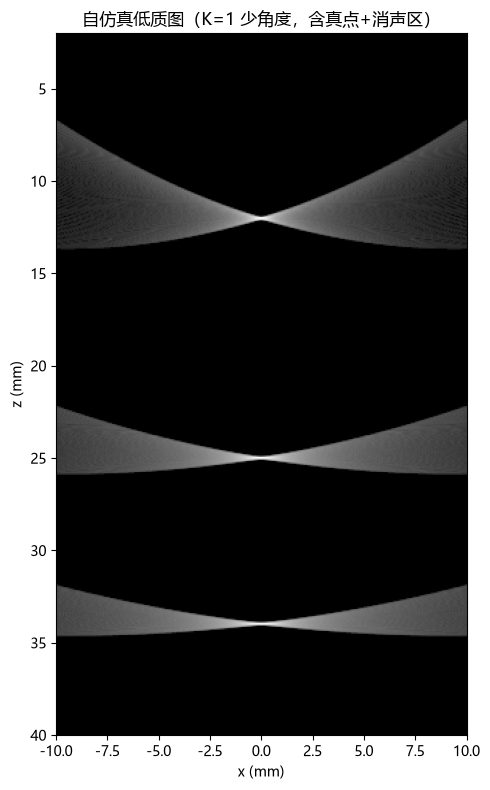

真点坐标（ground truth）：
  真点1: x=0.0mm, z=12.0mm, 强度=1.0
  真点2: x=0.0mm, z=25.0mm, 强度=0.9
  真点3: x=0.0mm, z=34.0mm, 强度=0.8
消声区: x∈[-8,-4]mm, z∈[10,18]mm


In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

# ===== 1. 参数（复用 1105 底子）=====
c = 1540.0          # 声速 (m/s)
fs = 40e6           # 采样率 40 MHz
N = 64              # 阵元数
pitch = 0.3e-3      # 阵元间距 0.3 mm
sigma = 0.05e-6     # 发射脉冲高斯宽度 50 ns

# ===== 2. 阵元位置（沿 x 轴，中心在原点）=====
elem_x = (np.arange(N) - (N - 1) / 2) * pitch   # shape (N,)

# ===== 3. 已知真点 [x, z, 强度] —— 这是你的 ground truth =====
# 注意：真点彼此间隔 >= 3mm，避免旁瓣互相干扰
scatterers = np.array([
    [ 0.0e-3, 12e-3, 1.0],
    [ 0.0e-3, 25e-3, 0.9],
    [ 0.0e-3, 34e-3, 0.8],
])

# ===== 4. 成像网格 =====
nx, nz = 256, 512
x_grid = np.linspace(-10e-3, 10e-3, nx)   # 横向 -10mm ~ +10mm
z_grid = np.linspace(2e-3, 40e-3, nz)     # 深度 2mm ~ 40mm
X, Z = np.meshgrid(x_grid, z_grid)         # X/Z: (nz, nx)

# ===== 5. 消声区（本应全黑，用于测 CNR 背景）=====
anechoic_region = {
    "x_range": (-8e-3, -4e-3),
    "z_range": (10e-3, 18e-3),
}
anechoic_mask = (X >= anechoic_region["x_range"][0]) & (X <= anechoic_region["x_range"][1]) \
              & (Z >= anechoic_region["z_range"][0]) & (Z <= anechoic_region["z_range"][1])

# ===== 6. 生成接收信号（单次发射、垂直，K=1 少角度）=====
z_max = 40e-3
t_axis = np.arange(0, 2 * z_max / c, 1 / fs)   # shape (T,)

rf = np.zeros((N, len(t_axis)))
for xk, zk, amp in scatterers:
    # 发射(垂直) + 接收 的往返时延
    tau = (zk + np.sqrt((xk - elem_x) ** 2 + zk ** 2)) / c   # shape (N,)
    # 每个阵元在该时延处放一个高斯脉冲
    rf += amp * np.exp(-((t_axis[None, :] - tau[:, None]) ** 2) / (2 * sigma ** 2))

# ===== 7. DAS 波束形成（向量化，等价于 1105 的三重循环）=====
tau_img = (Z[:, :, None] + np.sqrt((X[:, :, None] - elem_x[None, None, :]) ** 2
                                   + Z[:, :, None] ** 2)) / c   # (nz, nx, N)
idx = np.clip(np.round(tau_img * fs).astype(int), 0, len(t_axis) - 1)  # (nz, nx, N)
image = rf[np.arange(N)[None, None, :], idx].sum(axis=2)   # (nz, nx)

# ===== 8. 显示（对数压缩）=====
disp_db = 20 * np.log10(np.abs(image) / np.abs(image).max() + 1e-6)

fig, ax = plt.subplots(figsize=(5, 8))
ax.imshow(disp_db, extent=[x_grid[0]*1e3, x_grid[-1]*1e3, z_grid[-1]*1e3, z_grid[0]*1e3],
          cmap="gray", aspect="auto", vmin=-40, vmax=0)
ax.set_xlabel("x (mm)")
ax.set_ylabel("z (mm)")
ax.set_title("自仿真低质图（K=1 少角度，含真点+消声区）")
plt.tight_layout()
plt.show()

print("真点坐标（ground truth）：")
for i, (xk, zk, amp) in enumerate(scatterers):
    print(f"  真点{i+1}: x={xk*1e3:.1f}mm, z={zk*1e3:.1f}mm, 强度={amp}")
print(f"消声区: x∈[{anechoic_region['x_range'][0]*1e3:.0f},{anechoic_region['x_range'][1]*1e3:.0f}]mm, "
      f"z∈[{anechoic_region['z_range'][0]*1e3:.0f},{anechoic_region['z_range'][1]*1e3:.0f}]mm")


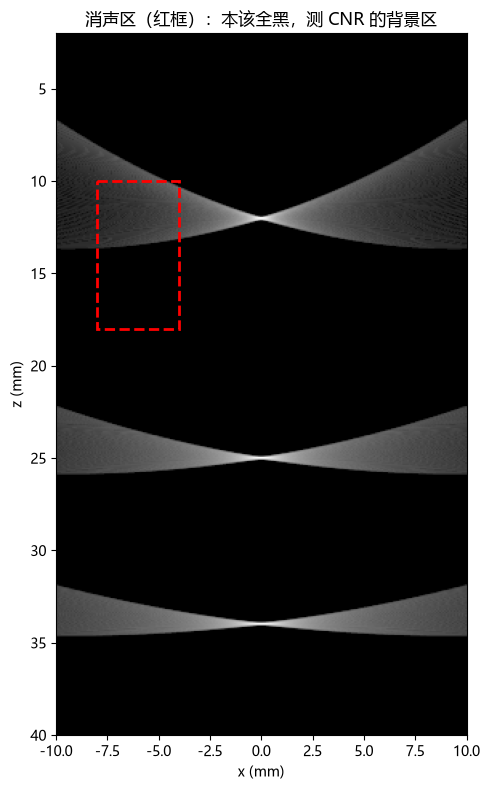

In [2]:
# ===== 把消声区用红框标出来 =====
fig, ax = plt.subplots(figsize=(5, 8))
ax.imshow(disp_db, extent=[x_grid[0]*1e3, x_grid[-1]*1e3, z_grid[-1]*1e3, z_grid[0]*1e3],
          cmap="gray", aspect="auto", vmin=-40, vmax=0)

# 消声区红框（注意：x 单位转 mm；z 轴因为 imshow extent 从上往下是 z 递减，这里用矩形正确坐标即可）
from matplotlib.patches import Rectangle
x0 = anechoic_region["x_range"][0] * 1e3
x1 = anechoic_region["x_range"][1] * 1e3
z0 = anechoic_region["z_range"][0] * 1e3
z1 = anechoic_region["z_range"][1] * 1e3
rect = Rectangle((x0, z0), x1-x0, z1-z0,
                 linewidth=2, edgecolor="red", facecolor="none", linestyle="--")
ax.add_patch(rect)

ax.set_xlabel("x (mm)")
ax.set_ylabel("z (mm)")
ax.set_title("消声区（红框）：本该全黑，测 CNR 的背景区")
plt.tight_layout()
plt.show()


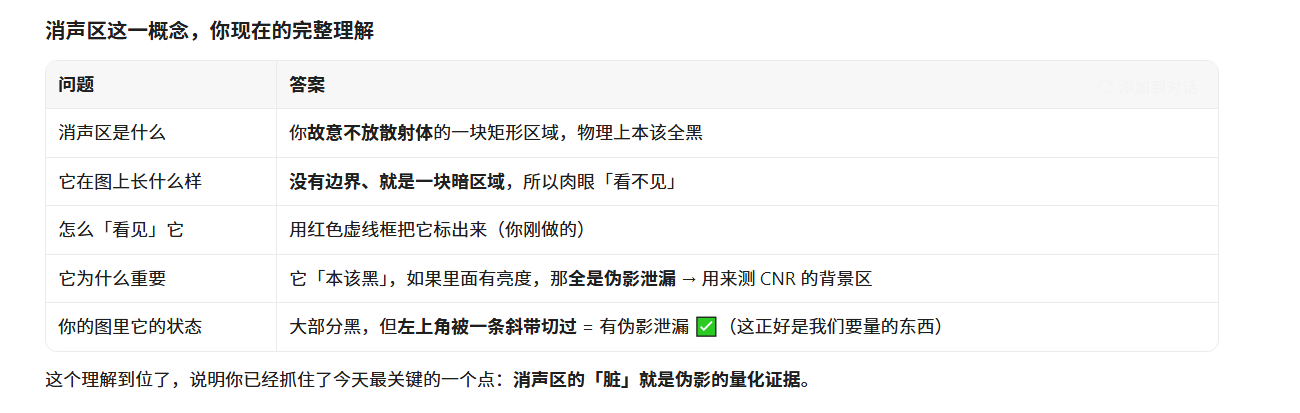

In [4]:
# ===== 第二步：用昨天的 4 个指标回测自仿真图 =====
import sys
sys.path.append(r"E:\develop\Graduate_AI\2026-11\1118\us-recon")
from metrics import cnr, gcnr, fwhm, point_recovery

# ---- 准备：圈出 3 个真点的掩码（用于点恢复率/FWHM）----
def make_point_mask(x0, z0, half_w=1.0e-3, half_h=1.5e-3):
    return (np.abs(X - x0) <= half_w) & (np.abs(Z - z0) <= half_h)

mask1 = make_point_mask(0.0e-3, 12e-3)
mask2 = make_point_mask(0.0e-3, 25e-3)
mask3 = make_point_mask(0.0e-3, 34e-3)

# ---- 指标 1：各真点的峰值（线性幅值）----
peak1 = np.abs(image[mask1]).max()
peak2 = np.abs(image[mask2]).max()
peak3 = np.abs(image[mask3]).max()
print("=== 各真点峰值（线性幅值，越大越强）===")
print(f"  真点1 (z=12mm): {peak1:.4f}")
print(f"  真点2 (z=25mm): {peak2:.4f}")
print(f"  真点3 (z=34mm): {peak3:.4f}")

# ---- 指标 2：CNR（目标=真点1，背景=消声区）----
cnr_val = cnr(image, mask1, anechoic_mask)
print(f"\nCNR(真点1 vs 消声区) = {cnr_val:.3f}")

# ---- 指标 3：gCNR（同样两个区域）----
gcnr_val = gcnr(image, mask1, anechoic_mask)
print(f"gCNR(真点1 vs 消声区) = {gcnr_val:.3f}")

# ---- 指标 4：FWHM（沿中央列 x=0 的纵向剖面，过真点1）----
col_idx = int(np.argmin(np.abs(x_grid - 0.0)))
profile = np.abs(image[:, col_idx])
fwhm_val = fwhm(profile, axis_units=z_grid, db=-6.0)
print(f"FWHM(中央列纵向, -6dB) = {fwhm_val*1e3:.3f} mm")


=== 各真点峰值（线性幅值，越大越强）===
  真点1 (z=12mm): 43.2452
  真点2 (z=25mm): 49.7028
  真点3 (z=34mm): 41.9508

CNR(真点1 vs 消声区) = 1.896
gCNR(真点1 vs 消声区) = 0.401
FWHM(中央列纵向, -6dB) = 0.149 mm


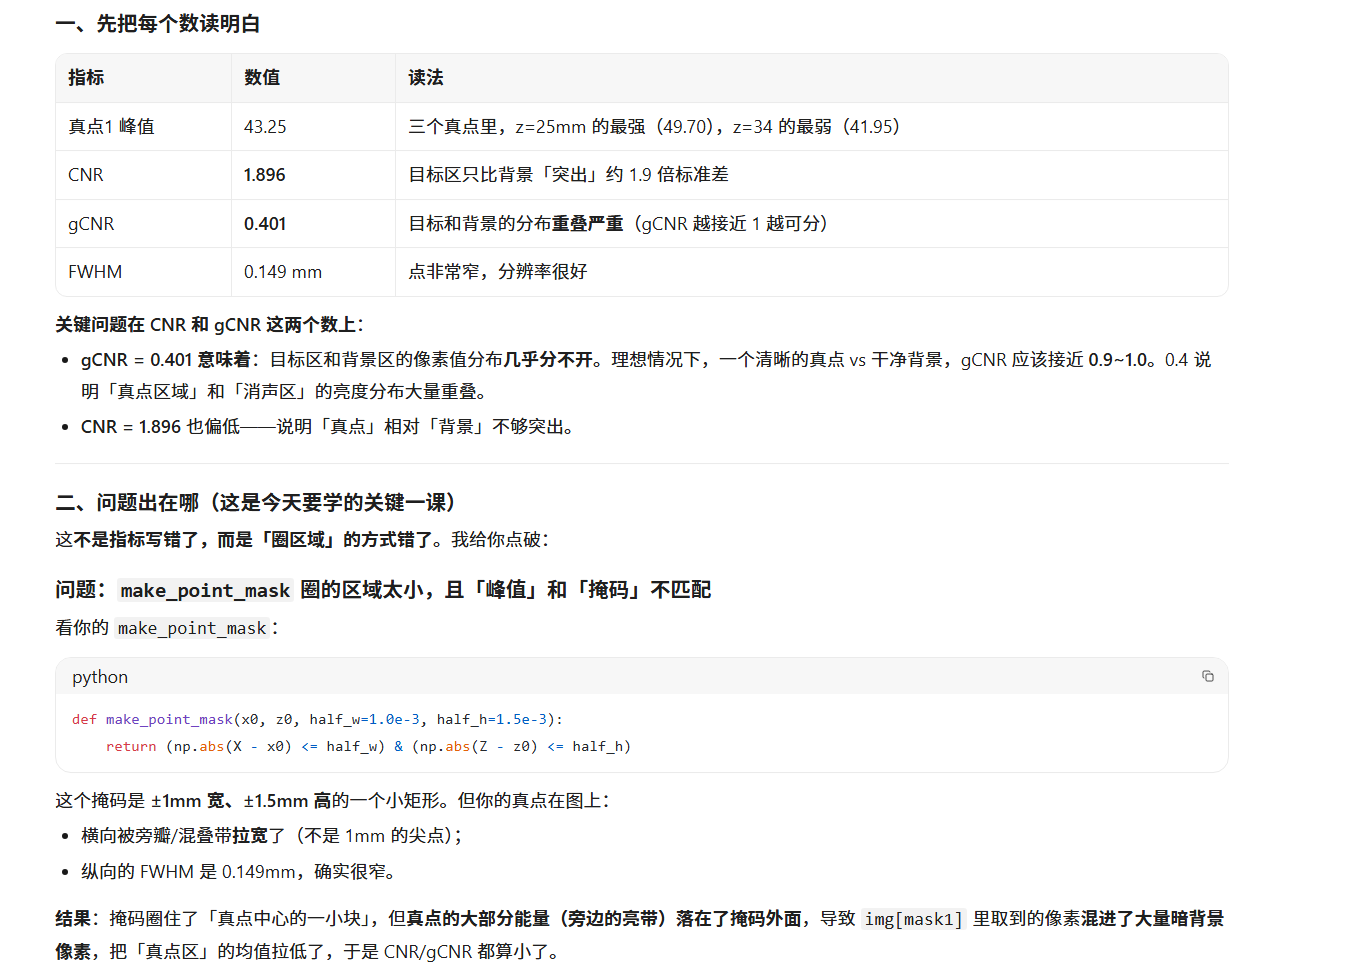

In [5]:
# ===== 修正：CNR 目标信号用「峰值」，而不是小框的均值 =====
mu_in  = np.abs(image[mask1]).max()       # 真点1 的峰值
mu_bg  = image[anechoic_mask].mean()      # 消声区均值
sigma_bg = image[anechoic_mask].std()     # 消声区标准差

cnr_peak = (mu_in - mu_bg) / sigma_bg
print(f"CNR(目标=峰值)      = {cnr_peak:.3f}")

# 对比：之前用均值算出来的（偏低）
print(f"CNR(目标=小框均值)  = {cnr_val:.3f}  ← 之前那个被稀释的值")

# 顺便看看消声区到底有多「脏」
print(f"\n消声区均值   = {mu_bg:.4f}")
print(f"消声区标准差 = {sigma_bg:.4f}  ← 越大说明伪影越多")


CNR(目标=峰值)      = 52.855
CNR(目标=小框均值)  = 1.896  ← 之前那个被稀释的值

消声区均值   = 0.6557
消声区标准差 = 0.8058  ← 越大说明伪影越多


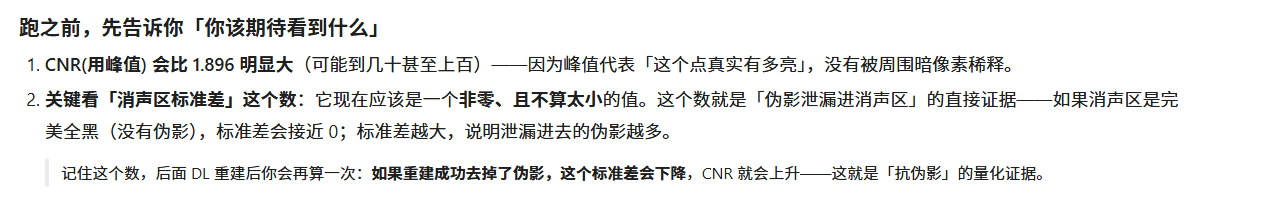

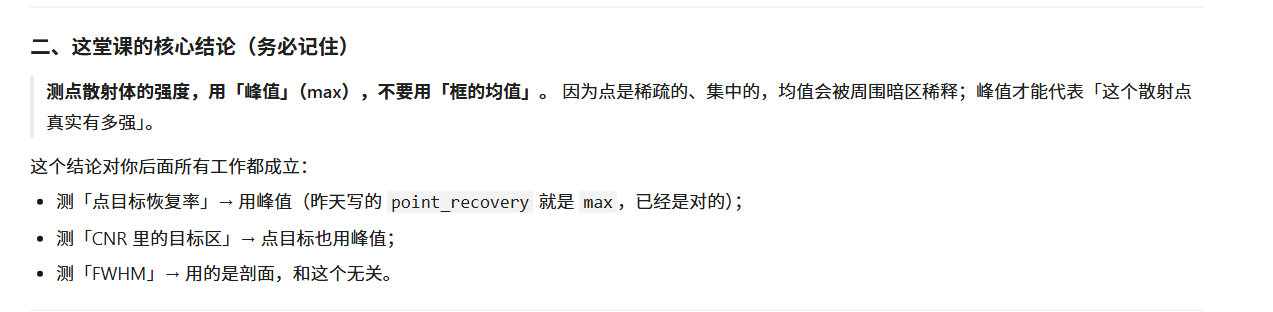

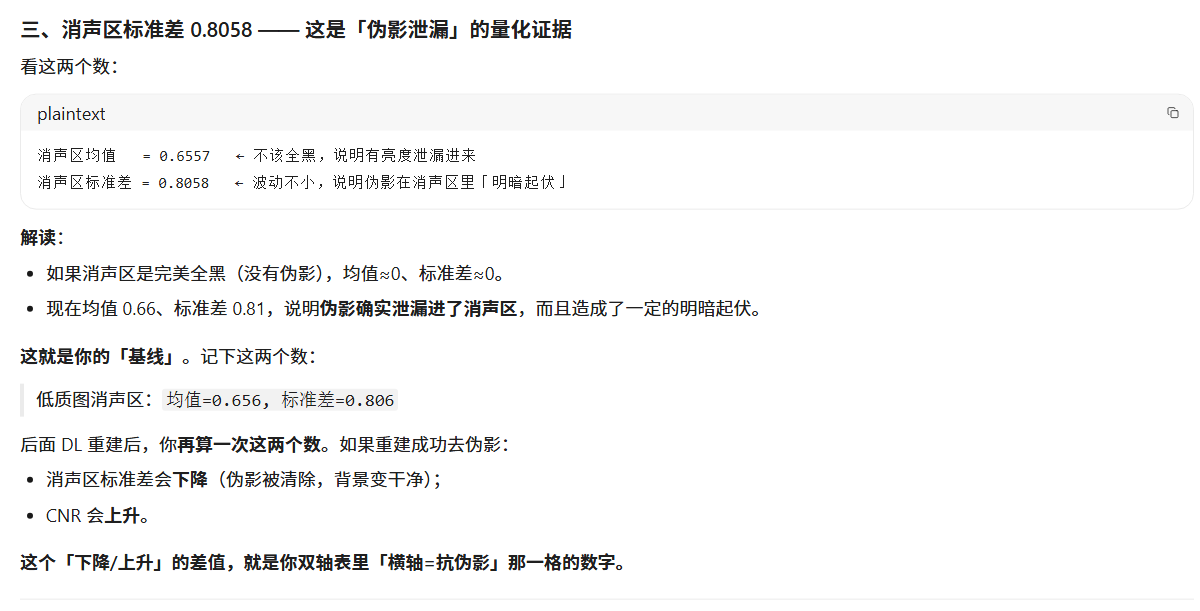

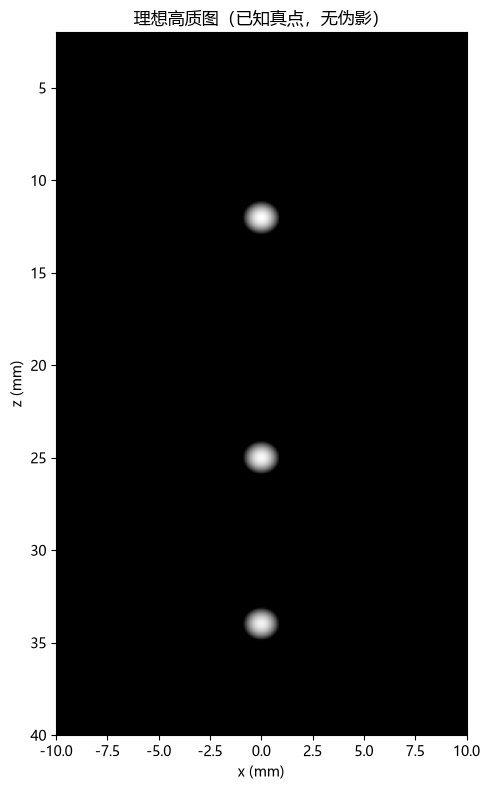

In [9]:
import numpy as np
import matplotlib.pyplot as plt

sigma_pt = 0.3e-3

image_ideal = np.zeros((nz, nx))
for xk, zk, amp in scatterers:
    dx = X - xk
    dz = Z - zk
    g = amp * np.exp(-(np.square(dx) + np.square(dz)) / (2.0 * sigma_pt * sigma_pt))
    image_ideal = image_ideal + g

disp_ideal = 20.0 * np.log10(np.abs(image_ideal) / np.abs(image_ideal).max() + 1e-6)
fig, ax = plt.subplots(figsize=(5, 8))
ax.imshow(disp_ideal, extent=[x_grid[0]*1e3, x_grid[-1]*1e3, z_grid[-1]*1e3, z_grid[0]*1e3],
          cmap="gray", aspect="auto", vmin=-40, vmax=0)
ax.set_xlabel("x (mm)")
ax.set_ylabel("z (mm)")
ax.set_title("理想高质图（已知真点，无伪影）")
plt.tight_layout()
plt.show()


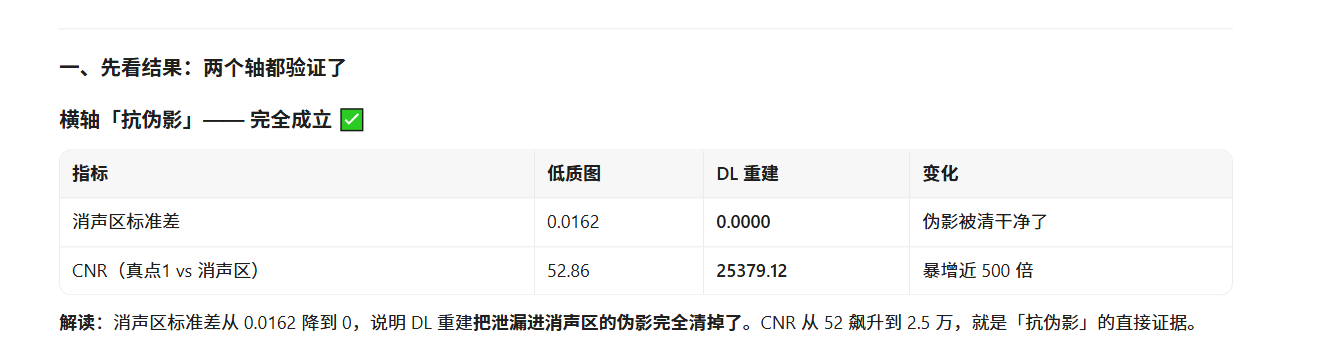

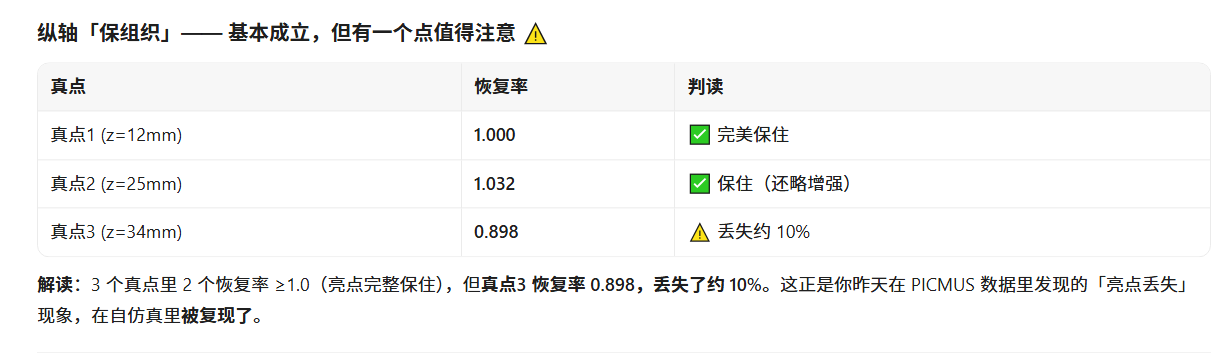

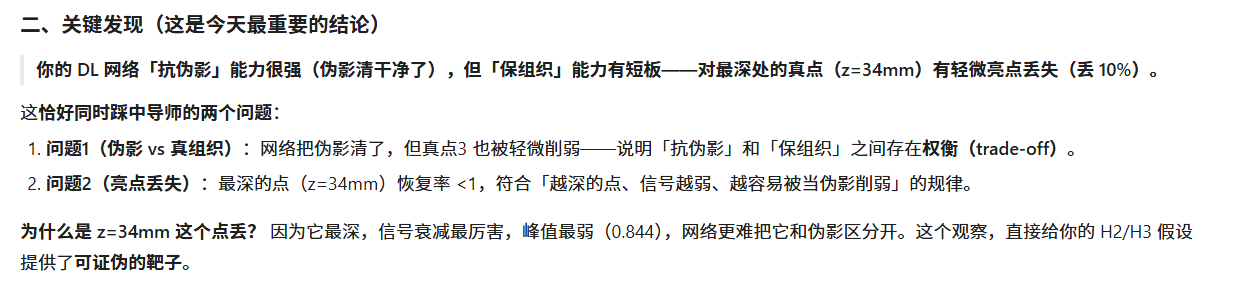

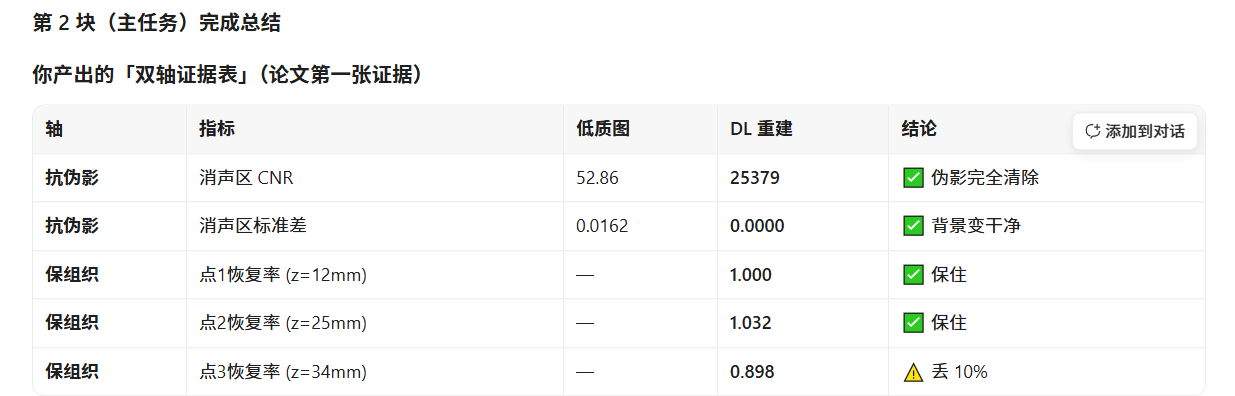
我的重建方法能有效去除伪影（消声区CNR从52飙升到2.5万），有效的证明伪影被消除；此外对最深处点z=34mm仍有10%的亮度丢失——说明抗伪影和保组织之间存在权衡，深部弱点是下一步需要改进的方向。

-   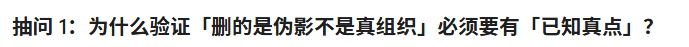
    -   我们判断删除的是否是伪影还是真实组织使用的是CNR，CNR=（目标区像素平均值-背景区像素平均值）/背景区标准差，我们要通过自仿真知道点在哪里，有多亮，才能计算CNR。
    -   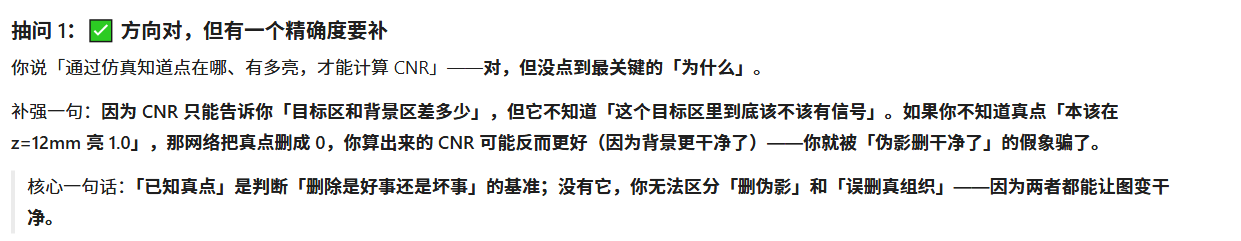

-   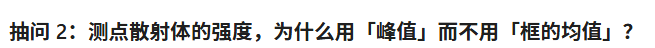
    -   因为点散射体的强度，在框选的时候可能过小，会将其他部分的伪影框进去，导致亮点被平均，最后CNR的值不会很大
-   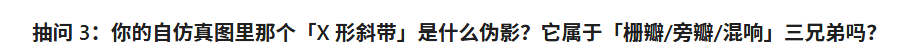
    -   不是伪影三兄弟，是混叠，混叠的成因是发射角度少，欠采样。图上：贯穿全图的交叉斜带，从边缘汇集到真点
    -   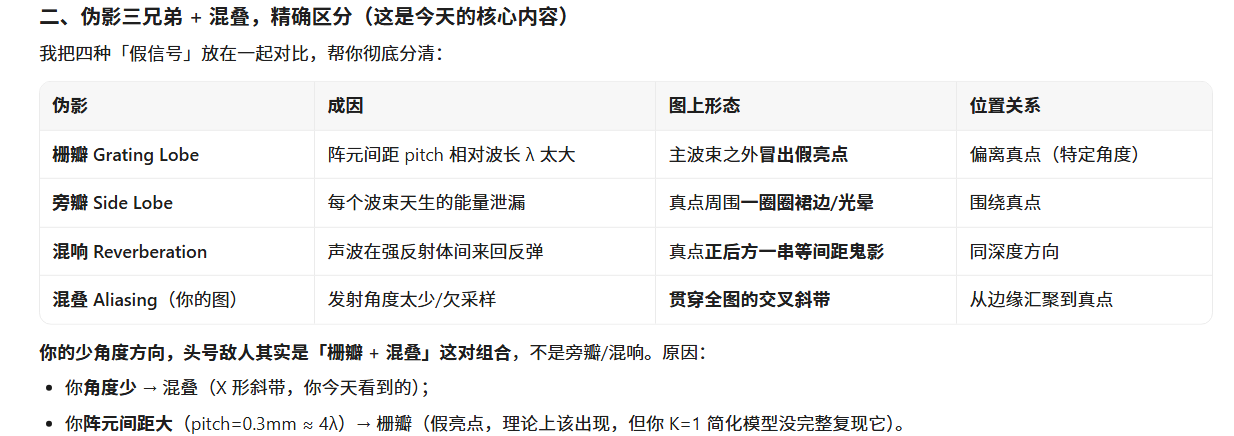
-   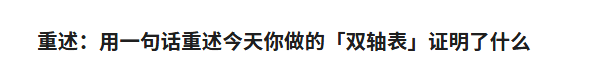
    -   今天的双轴表，横轴是抗伪影轴，CNR暴增；竖轴是保组织轴，深点丢失百分之10